# 03. Klastering kabupaten berdasarkan nama desanya

Pertanyaan: kalau model **tidak diberi tahu** provinsi atau wilayah apa pun, apakah kabupaten-kabupaten akan mengelompok sendiri menjadi wilayah budaya hanya dari kemiripan nama desanya?

Langkah:

1. Ubah setiap nama desa menjadi vektor TF-IDF n-gram karakter (sama seperti klasifikasi).
2. Setiap kabupaten diwakili oleh **rata-rata vektor** semua nama desanya.
3. Perkecil dimensi dengan TruncatedSVD.
4. Bandingkan K-Means dan Agglomerative (Ward) untuk k = 2 sampai 15.
5. Pilih k dan metode dengan silhouette score (tanpa label), lalu cek kecocokannya dengan provinsi dan wilayah asli memakai Adjusted Rand Index (ARI).
6. Gambar di peta.

Hasil yang disimpan: `data/processed/klaster_kabupaten.csv` dan grafik `reports/figures/03_*.png`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from matplotlib.patches import Patch
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import normalize

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.peta import gambar_peta

PROCESSED = ROOT / "data" / "processed"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
SEED = 42

# palet kategori (dataviz, sudah divalidasi untuk buta warna), urutan tetap
WARNA_KLASTER = ["#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac", "#008a17", "#6a4ce2"]
BIRU, ORANYE, ABU, TEKS, TEKS2 = "#257de0", "#f47230", "#c2c2c2", "#191919", "#666666"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": TEKS2, "xtick.color": TEKS2, "ytick.color": TEKS2,
    "axes.titlecolor": TEKS, "font.size": 9,
})

df = pd.read_parquet(PROCESSED / "desa_clean.parquet")
print(df.shape)

(83758, 9)


## 1. Vektor per kabupaten

Vectorizer sama dengan notebook 02: TF-IDF n-gram karakter 2 sampai 4 huruf. Vektor kabupaten adalah rata-rata vektor nama desanya, lalu dinormalisasi supaya kabupaten dengan banyak desa tidak lebih "berat".

In [2]:
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True)
X = vec.fit_transform(df["nama_bersih"])

kab = (df.groupby("kode_kabupaten")
       .agg(kabupaten=("kabupaten", "first"), provinsi=("provinsi", "first"),
            wilayah=("wilayah", "first"), jumlah_desa=("kode_desa", "size")))

# matriks rata-rata: baris = kabupaten, kolom = desa, isi = 1 / jumlah desa di kabupaten itu
baris = kab.index.get_indexer(df["kode_kabupaten"])
A = sp.csr_matrix((1 / kab["jumlah_desa"].values[baris], (baris, np.arange(len(df)))), shape=(len(kab), len(df)))
V = normalize(np.asarray((A @ X).todense()))
print("Matriks kabupaten:", V.shape)
print("Jumlah desa per kabupaten: min", kab["jumlah_desa"].min(), ", median", int(kab["jumlah_desa"].median()),
      ", maks", kab["jumlah_desa"].max())

Matriks kabupaten: (514, 28004)
Jumlah desa per kabupaten: min 6 , median 136 , maks 852


## 2. Reduksi dimensi

Ada sekitar 25 ribu n-gram, sedangkan kabupaten hanya 514. Di ruang sebesar itu jarak antartitik cenderung mirip semua, sehingga klastering kurang tajam. TruncatedSVD meringkasnya menjadi 20 dimensi.

Saat eksplorasi, 50 dan 100 dimensi juga dicoba. Pola klasternya mirip, tetapi silhouette-nya lebih rendah. Bagian 6 menunjukkan perbandingannya.

In [3]:
svd = TruncatedSVD(n_components=20, random_state=SEED)
Z = normalize(svd.fit_transform(V))
print(f"Variansi yang terwakili 20 komponen: {svd.explained_variance_ratio_.sum():.1%}")

Variansi yang terwakili 20 komponen: 38.9%


## 3. Memilih k dan metode

Untuk setiap k dihitung:

- **silhouette**: seberapa rapat dan terpisah klasternya. Tidak memakai label, jadi dipakai untuk **memilih**.
- **ARI terhadap provinsi** dan **ARI terhadap wilayah**: seberapa mirip klaster dengan pembagian resmi. Dipakai untuk **menilai** setelah memilih, bukan untuk memilih. ARI 0 berarti sama dengan acak, 1 berarti sama persis.

In [4]:
def klaster(metode, k, Z):
    if metode == "K-Means":
        return KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Z)
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)

METODE = ["K-Means", "Ward"]
hasil = []
for k in range(2, 16):
    for m in METODE:
        lab = klaster(m, k, Z)
        hasil.append({"k": k, "metode": m, "silhouette": silhouette_score(Z, lab),
                      "ARI_provinsi": adjusted_rand_score(kab["provinsi"], lab),
                      "ARI_wilayah": adjusted_rand_score(kab["wilayah"], lab)})
skor = pd.DataFrame(hasil)
skor.to_csv(ROOT / "reports" / "metrics_klastering.csv", index=False)
skor.pivot(index="k", columns="metode", values=["silhouette", "ARI_provinsi", "ARI_wilayah"]).round(3)

silhouette        ARI_provinsi        ARI_wilayah       
metode    K-Means   Ward      K-Means   Ward     K-Means   Ward
k                                                              
2           0.180  0.163        0.051  0.051       0.284  0.207
3           0.207  0.190        0.087  0.074       0.361  0.238
4           0.214  0.197        0.100  0.101       0.299  0.296
5           0.218  0.196        0.152  0.153       0.376  0.408
6           0.235  0.216        0.157  0.163       0.422  0.419
7           0.247  0.222        0.165  0.182       0.418  0.456
8           0.243  0.201        0.192  0.181       0.429  0.446
9           0.228  0.211        0.228  0.208       0.361  0.399
10          0.247  0.224        0.229  0.228       0.411  0.391
11          0.246  0.236        0.252  0.233       0.379  0.397
12          0.258  0.239        0.289  0.240       0.352  0.405
13          0.267  0.241        0.287  0.263       0.362  0.374
14          0.265  0.251        0.290  0.265       0.339  0.376
15          0.262  0.256        0.345  0.270       0.326  0.362

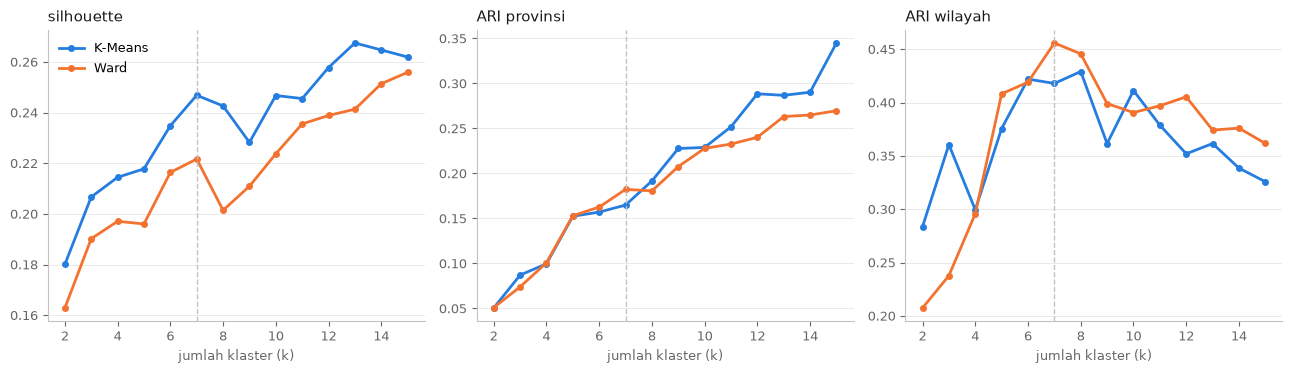

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, kolom in zip(axes, ["silhouette", "ARI_provinsi", "ARI_wilayah"]):
    for m, w in zip(METODE, [BIRU, ORANYE]):
        d = skor[skor["metode"] == m]
        ax.plot(d["k"], d[kolom], marker="o", markersize=4, linewidth=2, color=w, label=m)
    ax.axvline(7, color=ABU, linestyle="--", linewidth=1)
    ax.set_title(kolom.replace("_", " "), loc="left")
    ax.set_xlabel("jumlah klaster (k)")
    ax.grid(axis="y", color="#e7e7e7", linewidth=0.6)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGS / "03_pemilihan_k.png", dpi=150)
plt.show()

Silhouette tidak punya satu puncak tajam. Nilai tertingginya ada di k = 13 (sekitar 0,27), tetapi selisihnya dengan k = 7 (sekitar 0,25) kecil, dan semua nilainya rendah (di bawah 0,3), artinya batas antarklaster memang tidak tegas. Nama desa berubah perlahan dari satu daerah ke daerah tetangga, bukan berpindah tiba-tiba.

**k = 7** dipilih karena tiga alasan: (1) k = 7 adalah puncak lokal pertama silhouette untuk kedua metode, (2) 7 klaster masih bisa dijelaskan satu per satu di presentasi, sedangkan 13 terlalu banyak, (3) angkanya sama dengan jumlah wilayah besar, sehingga bisa dibandingkan langsung dengan pembagian 7 wilayah. Alasan (2) dan (3) adalah pertimbangan praktis, dan perlu ditulis terus terang di laporan.

Pada k = 7, metode dengan silhouette lebih tinggi dipakai sebagai hasil utama. Hasil metode lainnya tetap disimpan untuk perbandingan.

In [6]:
K = 7
s7 = skor[skor["k"] == K].set_index("metode")
UTAMA = s7["silhouette"].idxmax()
print(s7.round(3))
print("Metode utama:", UTAMA)

kab["klaster_kmeans"] = klaster("K-Means", K, Z)
kab["klaster_ward"] = klaster("Ward", K, Z)
kab["klaster"] = kab["klaster_kmeans" if UTAMA == "K-Means" else "klaster_ward"]

         k  silhouette  ARI_provinsi  ARI_wilayah
metode                                           
K-Means  7       0.247         0.165        0.418
Ward     7       0.222         0.182        0.456
Metode utama: K-Means


## 4. Isi tiap klaster

Supaya klaster bisa dibaca manusia, setiap klaster diberi ringkasan:

- provinsi yang paling banyak anggotanya
- n-gram yang paling menonjol (rata-rata TF-IDF klaster dikurangi rata-rata semua kabupaten)
- contoh nama desa yang paling sering muncul

Nama klaster dibuat otomatis dari 2 provinsi terbanyak, lalu dirapikan manual di laporan.

In [7]:
fitur = vec.get_feature_names_out()
rata_semua = V.mean(axis=0)
df["klaster"] = df["kode_kabupaten"].map(kab["klaster"])

ringkasan = []
for c in range(K):
    anggota = kab[kab["klaster"] == c]
    beda = V[(kab["klaster"] == c).values].mean(axis=0) - rata_semua
    top_ng = [fitur[j].replace(" ", "_") for j in np.argsort(-beda)[:8]]
    prov = anggota["provinsi"].value_counts()
    nama = df.loc[df["klaster"] == c, "nama_bersih"].value_counts().index[:5]
    ringkasan.append({
        "klaster": c, "jumlah_kabupaten": len(anggota),
        "provinsi_terbanyak": ", ".join(f"{p} ({n})" for p, n in prov.head(4).items()),
        "ngram_menonjol": " | ".join(top_ng),
        "nama_desa_tersering": ", ".join(nama),
        "nama_klaster": " / ".join(prov.index[:2]),
    })
ringkasan = pd.DataFrame(ringkasan).set_index("klaster")

# Label budaya, diberikan manual setelah membaca isi klaster di atas.
# Kuncinya nama otomatis (2 provinsi terbanyak). Kalau isi klaster berubah saat dijalankan ulang,
# kuncinya tidak cocok dan label kembali ke nama otomatis, jadi tidak ada label yang salah tempel.
LABEL_BUDAYA = {
    "Jawa Timur / Jawa Tengah": "Jawa",
    "Jawa Barat / Banten": "Sunda",
    "Aceh": "Aceh pesisir",
    "Sumatera Barat / Sumatera Selatan": "Melayu (pesisir Sumatera dan Kalimantan)",
    "Sulawesi Selatan / Sulawesi Utara": "Batak, Bugis-Makassar, Minahasa, Dayak pedalaman",
    "Sulawesi Tenggara / Nusa Tenggara Timur": "Indonesia timur (Sultra, NTT, Maluku Utara, Nias)",
    "Papua / Papua Pegunungan": "Papua",
}
ringkasan["nama_klaster"] = ringkasan["nama_klaster"].map(LABEL_BUDAYA).fillna(ringkasan["nama_klaster"])
pd.set_option("display.max_colwidth", 120)
ringkasan

,jumlah_kabupaten,provinsi_terbanyak,ngram_menonjol,nama_desa_tersering,nama_klaster
klaster,,,,,
0,72,"Jawa Timur (34), Jawa Tengah (30), Daerah Istimewa Yogyakarta (5), Lampung (2)",jo | jo_ | o_ | ej | ejo | rejo | rej | n_,"sidomulyo, sukorejo, sidorejo, sumberejo, wonorejo",Jawa
1,69,"Sulawesi Tenggara (17), Nusa Tenggara Timur (12), Sulawesi Tengah (8), Maluku Utara (8)",a_ | ol | o_ | wa | e_ | _w | la | _l,"mataiwoi, kampung baru, pasir putih, mekar jaya, beringin jaya","Indonesia timur (Sultra, NTT, Maluku Utara, Nias)"
2,15,Aceh (15),eu | eun | ue | h_ | e_ | ng_ | g_ | blan,"gampong baro, blang dalam, keutapang, blang cut, meunasah teungoh",Aceh pesisir
3,42,"Jawa Barat (27), Banten (7), Jawa Tengah (5), Lampung (2)",_ci | ci | _c | ar | ka | ja | suka | sari,"mekarsari, mekarjaya, sukamulya, sukamaju, sukamanah",Sunda
4,183,"Sumatera Barat (18), Sumatera Selatan (17), Sumatera Utara (15), Kalimantan Barat (14)",ng_ | g_ | ung | un | ang_ | ung_ | ai_ | ng,"mekar jaya, suka maju, mekar sari, kampung baru, sukaraja",Melayu (pesisir Sumatera dan Kalimantan)
5,80,"Sulawesi Selatan (23), Sulawesi Utara (14), Sumatera Utara (13), Sulawesi Barat (6)",on | _b | g_ | ng_ | to | at | _l | e_,"benteng, polewali, tapian nauli, pardomuan, bonan dolok","Batak, Bugis-Makassar, Minahasa, Dayak pedalaman"
6,53,"Papua (9), Papua Pegunungan (8), Papua Barat (7), Papua Tengah (7)",_w | _y | wa | i_ | _wa | _o | ai | ma,"pasir putih, muara, kampung baru, trikora, weri",Papua


Contoh pembagian di dalam provinsi. Ini bagian yang paling menarik: batas klaster sering memotong batas provinsi mengikuti batas suku.

In [8]:
kab["nama_klaster"] = kab["klaster"].map(ringkasan["nama_klaster"])
for p in ["Aceh", "Sumatera Utara", "Lampung", "Kalimantan Tengah", "Nusa Tenggara Barat"]:
    print(f"== {p}")
    d = kab[kab["provinsi"] == p].groupby("nama_klaster")["kabupaten"]
    for nama, isi in d:
        print(f"   {nama}: {', '.join(isi.str.replace('Kabupaten ', ''))}")

== Aceh
   Aceh pesisir: Aceh Selatan, Aceh Timur, Aceh Barat, Aceh Besar, Pidie, Aceh Utara, Bireuen, Aceh Barat Daya, Aceh Jaya, Nagan Raya, Pidie Jaya, Kota Banda Aceh, Kota Sabang, Kota Lhokseumawe, Kota Langsa
   Melayu (pesisir Sumatera dan Kalimantan): Aceh Tenggara, Aceh Tengah, Simeulue, Aceh Singkil, Gayo Lues, Aceh Tamiang, Bener Meriah, Kota Subulussalam
== Sumatera Utara
   Batak, Bugis-Makassar, Minahasa, Dayak pedalaman: Tapanuli Tengah, Tapanuli Utara, Tapanuli Selatan, Simalungun, Dairi, Toba, Mandailing Natal, Humbang Hasundutan, Samosir, Padang Lawas Utara, Padang Lawas, Kota Sibolga, Kota Padangsidimpuan
   Indonesia timur (Sultra, NTT, Maluku Utara, Nias): Nias, Nias Selatan, Nias Utara, Nias Barat, Kota Gunungsitoli
   Melayu (pesisir Sumatera dan Kalimantan): Langkat, Karo, Deli Serdang, Asahan, Labuhanbatu, Pakpak Bharat, Serdang Bedagai, Batu Bara, Labuhanbatu Selatan, Labuhanbatu Utara, Kota Medan, Kota Pematangsiantar, Kota Tanjungbalai, Kota Binjai, Kota Teb

In [9]:
pd.crosstab(kab["klaster"], kab["wilayah"]).rename(index=ringkasan["nama_klaster"])

wilayah,Bali dan Nusa Tenggara,Jawa,Kalimantan,Maluku,Papua,Sulawesi,Sumatera
klaster,,,,,,,
Jawa,1,69,0,0,0,0,2
"Indonesia timur (Sultra, NTT, Maluku Utara, Nias)",15,0,0,14,2,33,5
Aceh pesisir,0,0,0,0,0,0,15
Sunda,0,40,0,0,0,0,2
Melayu (pesisir Sumatera dan Kalimantan),12,5,50,0,0,0,116
"Batak, Bugis-Makassar, Minahasa, Dayak pedalaman",7,5,6,0,0,48,14
Papua,6,0,0,7,40,0,0


## 5. Peta

Atas: klaster hasil metode utama. Bawah: pembagian 7 wilayah resmi sebagai pembanding. Warna klaster tidak punya arti urutan; yang penting adalah batas-batasnya.

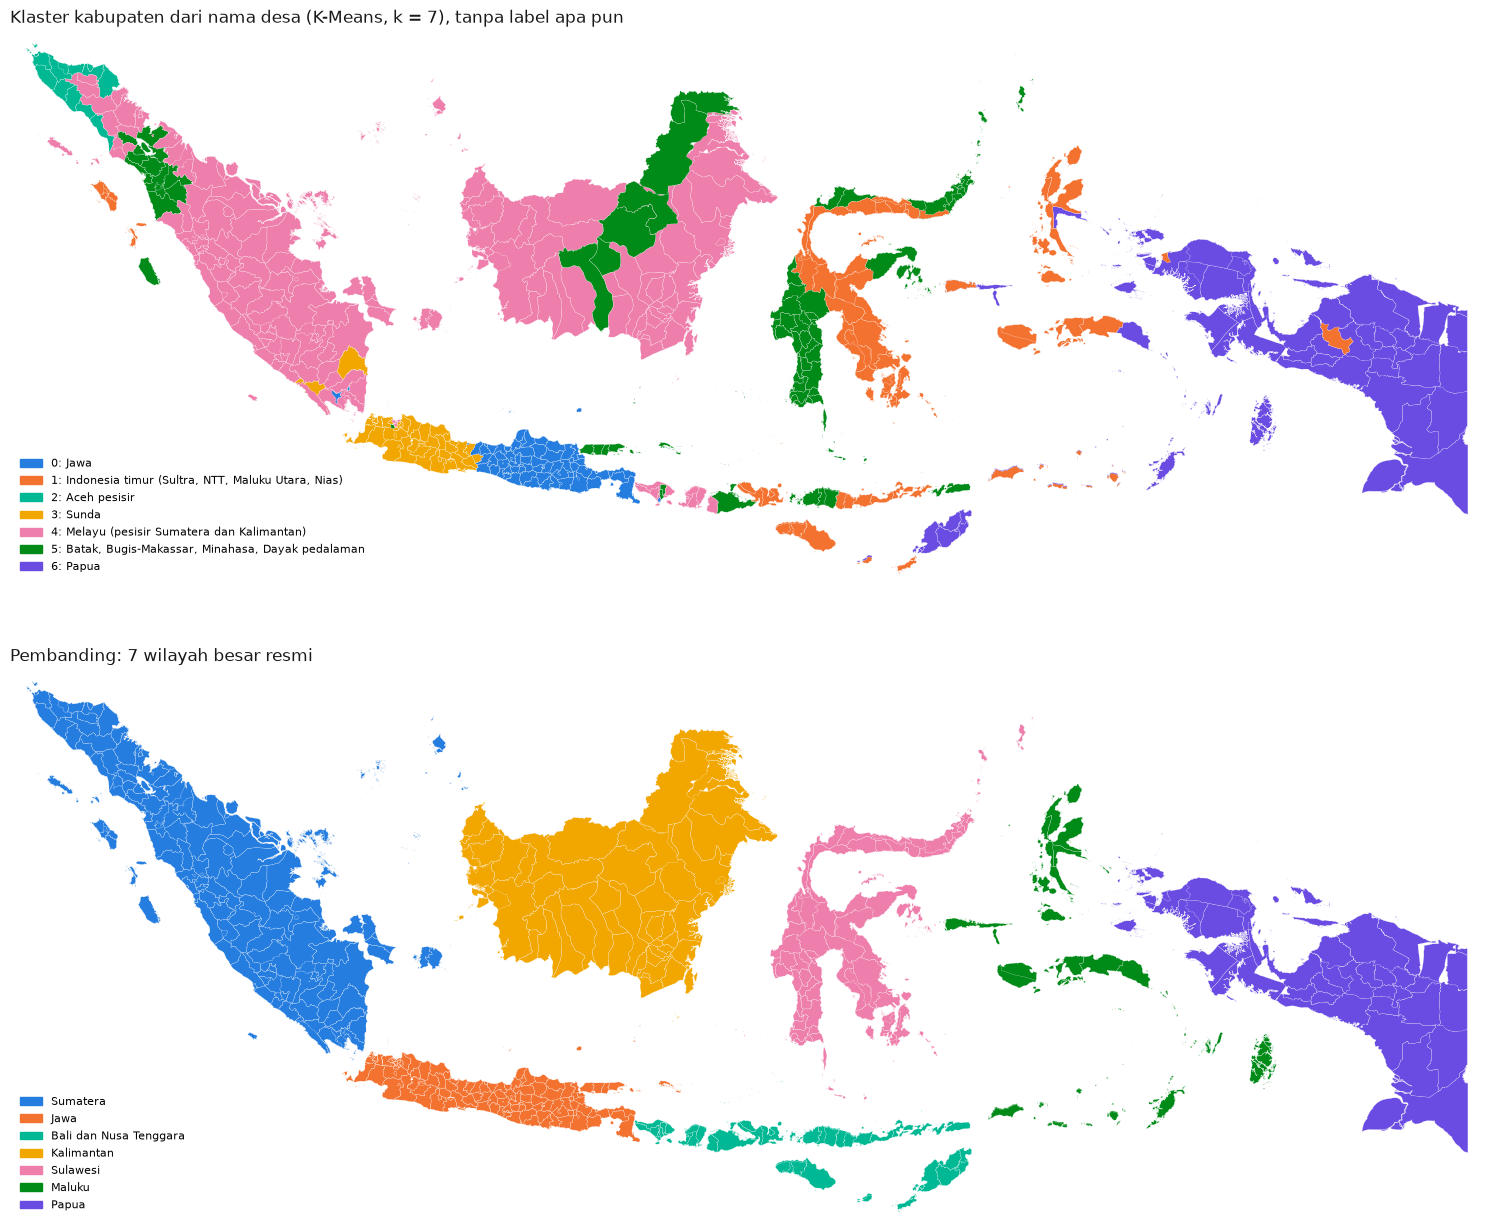

In [10]:
URUT_WIL = ["Sumatera", "Jawa", "Bali dan Nusa Tenggara", "Kalimantan", "Sulawesi", "Maluku", "Papua"]

fig, axes = plt.subplots(2, 1, figsize=(15, 13))
gambar_peta(axes[0], warna={k: WARNA_KLASTER[c] for k, c in kab["klaster"].items()})
axes[0].set_title(f"Klaster kabupaten dari nama desa ({UTAMA}, k = {K}), tanpa label apa pun", loc="left", fontsize=12)
axes[0].legend(handles=[Patch(color=WARNA_KLASTER[c], label=f"{c}: {ringkasan.loc[c, 'nama_klaster']}") for c in range(K)],
               loc="lower left", frameon=False, fontsize=8)

wil_ke_warna = {w: WARNA_KLASTER[i] for i, w in enumerate(URUT_WIL)}
gambar_peta(axes[1], warna={k: wil_ke_warna[w] for k, w in kab["wilayah"].items()})
axes[1].set_title("Pembanding: 7 wilayah besar resmi", loc="left", fontsize=12)
axes[1].legend(handles=[Patch(color=wil_ke_warna[w], label=w) for w in URUT_WIL],
               loc="lower left", frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGS / "03_peta_klaster.png", dpi=150)
plt.show()

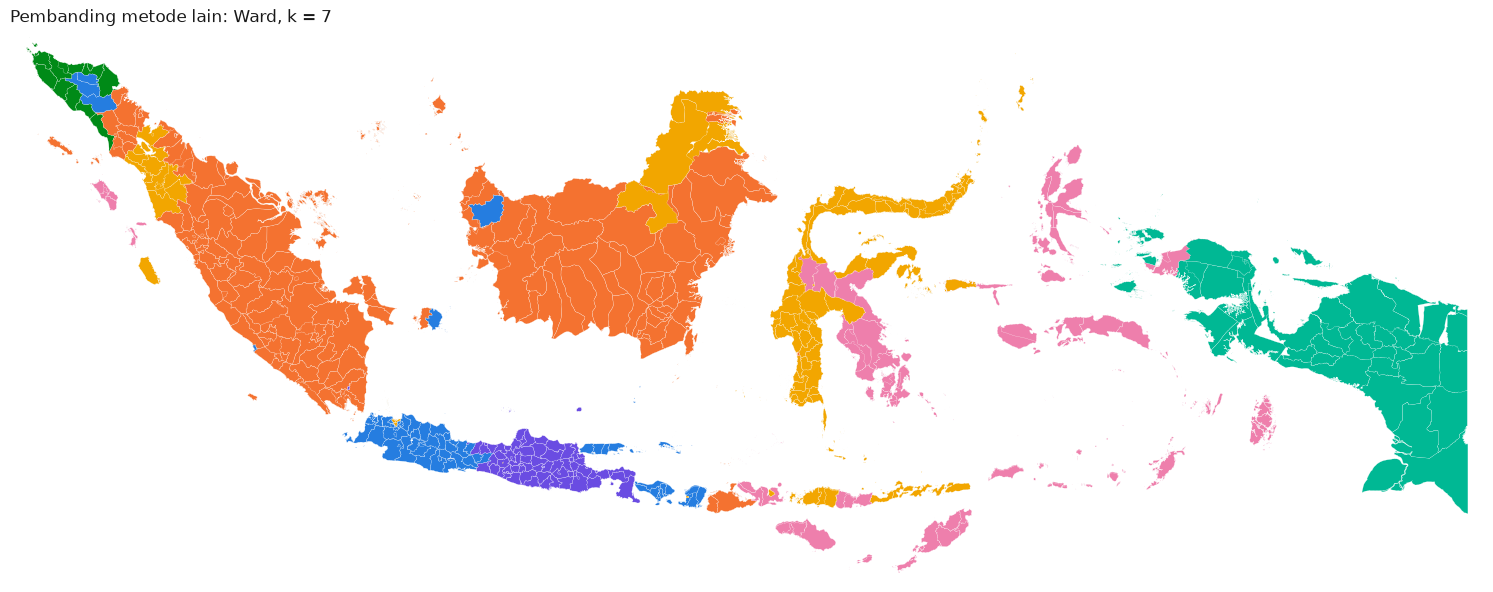

In [11]:
lain = "klaster_ward" if UTAMA == "K-Means" else "klaster_kmeans"
fig, ax = plt.subplots(figsize=(15, 6.5))
gambar_peta(ax, warna={k: WARNA_KLASTER[c] for k, c in kab[lain].items()})
ax.set_title(f"Pembanding metode lain: {'Ward' if UTAMA == 'K-Means' else 'K-Means'}, k = {K}", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig(FIGS / "03_peta_klaster_pembanding.png", dpi=150)
plt.show()

## 6. Kepekaan terhadap jumlah dimensi SVD

Cek apakah kesimpulan berubah kalau jumlah dimensi SVD diganti.

In [12]:
peka = []
for n in [10, 20, 50, 100]:
    Zn = normalize(TruncatedSVD(n_components=n, random_state=SEED).fit_transform(V))
    for m in METODE:
        lab = klaster(m, K, Zn)
        peka.append({"dimensi_svd": n, "metode": m, "silhouette": silhouette_score(Zn, lab),
                     "ARI_wilayah": adjusted_rand_score(kab["wilayah"], lab),
                     "ARI_dengan_hasil_utama": adjusted_rand_score(kab["klaster"], lab)})
pd.DataFrame(peka).round(3)

,dimensi_svd,metode,silhouette,ARI_wilayah,ARI_dengan_hasil_utama
0,10,K-Means,0.330,0.385,0.870
1,10,Ward,0.310,0.444,0.692
2,20,K-Means,0.247,0.418,1.000
3,20,Ward,0.222,0.456,0.716
4,50,K-Means,0.139,0.427,0.627
5,50,Ward,0.168,0.426,0.723
6,100,K-Means,0.126,0.398,0.729
7,100,Ward,0.124,0.373,0.637


## 7. Simpan

In [13]:
simpan = kab.reset_index()[["kode_kabupaten", "kabupaten", "provinsi", "wilayah", "klaster",
                            "klaster_kmeans", "klaster_ward"]]
simpan["nama_klaster"] = simpan["klaster"].map(ringkasan["nama_klaster"])
simpan.to_csv(PROCESSED / "klaster_kabupaten.csv", index=False)
ringkasan.to_csv(ROOT / "reports" / "ringkasan_klaster.csv")
print(simpan.shape)
simpan.head()

(514, 8)


,kode_kabupaten,kabupaten,provinsi,wilayah,klaster,klaster_kmeans,klaster_ward,nama_klaster
0,11.01,Kabupaten Aceh Selatan,Aceh,Sumatera,2,2,5,Aceh pesisir
1,11.02,Kabupaten Aceh Tenggara,Aceh,Sumatera,4,4,1,Melayu (pesisir Sumatera dan Kalimantan)
2,11.03,Kabupaten Aceh Timur,Aceh,Sumatera,2,2,5,Aceh pesisir
3,11.04,Kabupaten Aceh Tengah,Aceh,Sumatera,4,4,0,Melayu (pesisir Sumatera dan Kalimantan)
4,11.05,Kabupaten Aceh Barat,Aceh,Sumatera,2,2,5,Aceh pesisir


## 8. Interpretasi (draf untuk laporan)

Cek ulang poin-poin ini setiap kali notebook dijalankan ulang, karena nomor klaster bisa berubah.

1. **Tanpa diberi label apa pun, klaster menemukan batas budaya, bukan batas pulau.** Pulau Jawa terbelah menjadi Sunda (Jawa Barat dan Banten) dan Jawa (Jawa Tengah, DIY, Jawa Timur), tepat di sekitar batas bahasa.
2. **Batas klaster memotong batas provinsi mengikuti batas suku.**
   - Aceh: klaster "Aceh" hanya berisi Aceh pesisir. Daerah Gayo dan Alas (Aceh Tengah, Aceh Tenggara, Gayo Lues, Bener Meriah) masuk klaster lain.
   - Sumatera Utara terbelah tiga: tanah Batak (Tapanuli, Toba, Samosir, Mandailing), pesisir Melayu (Langkat, Deli Serdang, Asahan), dan Nias.
   - Lampung: Kota Metro dan Pringsewu masuk klaster Jawa, konsisten dengan jejak transmigrasi di notebook 04.
   - Kalimantan Tengah: kabupaten pedalaman Dayak (Katingan, Gunung Mas, Murung Raya) terpisah dari pesisir Melayu.
3. **Sebagian besar Sumatera dan Kalimantan bergabung dalam satu klaster Melayu**, karena kosakata yang sama (sungai, tanjung, pulau, teluk, mekar jaya). Ini konsisten dengan temuan di notebook 04 bahwa sekitar seperempat desa Kalimantan ditebak Sumatera.
4. **Klaster "pedalaman" menggabungkan Batak, Bugis-Makassar, Minahasa, dan Dayak**, yang lokasinya berjauhan. Penjelasan yang mungkin: nama-nama di daerah ini sama-sama memakai bentuk Austronesia yang tidak tersentuh pengaruh Melayu, seperti akhiran -on, -ng dan awalan b-. Ini hipotesis untuk dibahas, bukan kesimpulan.
5. **Yang tidak berhasil: Bali tidak membentuk klaster sendiri**, dan sebagian besar kabupatennya masuk klaster Melayu. Dengan k = 7, pola Bali kalah oleh kelompok yang lebih besar. Ini keterbatasan yang perlu ditulis jujur.
6. ARI terhadap wilayah resmi sekitar 0,42 (K-Means) dan 0,46 (Ward): jauh di atas acak (0), tetapi bukan 1. Pembagian "budaya nama" mirip, tetapi tidak sama dengan pembagian administratif, dan selisih itulah yang menarik.